# Dry Bean Classification: 5 ML Models and 6 Evaluation Metrics
**Course:** Machine Learning (AIMLZG565)

This notebook trains **five classifiers** on the **same dataset** (the UCI Dry Bean dataset) and evaluates each one with **six metrics**.

| # | Model | Where it is covered in the slides |
|---|---|---|
| 1 | Logistic Regression | Lecture 11 (Bayesian Learning): *MLE for Logistic Regression*, *Generative vs Discriminative*, *Logistic Regression vs Naive Bayes* |
| 2 | Decision Tree Classifier | Module 5 (Decision Tree); CS-15: *Interpretability in Decision Trees*; CS-12: trees as the base learner for Random Forest |
| 3 | K-Nearest Neighbor | Lecture 9 (Instance Based Learning) |
| 4 | Naive Bayes (**Gaussian**) | Lecture 11: *Continuous features* and *The Gaussian Probability Distribution* |
| 5 | Support Vector Machine | Lecture 10 (SVM): max margin, soft margin, kernel trick, multi-class |

**Metrics:** Accuracy, AUC, Precision, Recall, F1 Score, Matthews Correlation Coefficient (MCC).
The formulas for Accuracy, Precision, Recall and F1 come from CS-15 (*Methods and Metrics for Model Evaluation*). The train / validation / test and cross-validation workflow comes from the end of Lecture 9 (*Evaluating Classifier Performance*).

> **How to run in Google Colab:** choose *Runtime → Run all*. When **Step 2** asks for a file, upload the dataset zip (`drybeandataset.zip`) or the `Dry_Bean_Dataset.xlsx` file. The whole notebook takes about 2–4 minutes on a standard Colab CPU.

## Step 1: Import libraries
* **pandas / numpy**: load and handle the table of bean measurements.
* **matplotlib / seaborn**: plots.
* **scikit-learn**: all five models, preprocessing, cross-validation and metrics. The *Model Guide* slide in CS-15 is the scikit-learn algorithm cheat-sheet. It routes a labeled *category* problem with fewer than 100K samples to **Linear SVC → KNeighbors Classifier → SVC / Ensembles**, and text data to **Naive Bayes**. That is the same family of models used here.

`RANDOM_STATE = 42` fixes all randomness so the results can be reproduced.

In [1]:
import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_curve, auc)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.precision", 4)

# One fixed colour per bean class / per model (colour follows the entity everywhere)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "lines.linewidth": 2})
print("Libraries loaded.")

Libraries loaded.


## Step 2: Load the dataset
The **Dry Bean dataset** (UCI, Koklu & Ozkan 2020) contains **13,611 images of dry beans** from 7 registered varieties. Each image was reduced to **16 numeric shape features**: 12 dimensions (Area, Perimeter, Major/Minor axis length, …) and 4 *shape factors*.

The cell below:
1. reuses the file if it is already in the Colab session, otherwise
2. opens an **upload** button. Upload the `.zip` (it is extracted automatically) or the `.xlsx`.

*(Another option is to put the file in Google Drive, mount it with `from google.colab import drive; drive.mount('/content/drive')`, and set `DATA_FILE` to its path.)*

In [2]:
def find_dataset():
    hits = glob.glob("**/Dry_Bean_Dataset.xlsx", recursive=True)
    return hits[0] if hits else None

DATA_FILE = find_dataset()

if DATA_FILE is None:
    try:
        from google.colab import files          # only exists inside Colab
        print("Please upload drybeandataset.zip or Dry_Bean_Dataset.xlsx ...")
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith(".zip"):
                with zipfile.ZipFile(name) as z:
                    z.extractall("dry_bean_data")
        DATA_FILE = find_dataset()
    except ImportError:
        pass

if DATA_FILE is None:
    raise FileNotFoundError("Dry_Bean_Dataset.xlsx not found - upload it and re-run this cell.")

df = pd.read_excel(DATA_FILE)
print("Loaded:", DATA_FILE)
print("Shape :", df.shape)
df.head()

Loaded: Dry_Bean_Dataset.xlsx
Shape : (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.1781,173.8887,1.1972,0.5498,28715,190.1411,0.7639,0.9889,0.9580,0.9134,0.0073,0.0031,0.8342,0.9987,SEKER
1,28734,638.018,200.5248,182.7344,1.0974,0.4118,29172,191.2728,0.7840,0.9850,0.8870,0.9539,0.0070,0.0036,0.9099,0.9984,SEKER
2,29380,624.110,212.8261,175.9311,1.2097,0.5627,29690,193.4109,0.7781,0.9896,0.9478,0.9088,0.0072,0.0030,0.8259,0.9991,SEKER
3,30008,645.884,210.5580,182.5165,1.1536,0.4986,30724,195.4671,0.7827,0.9767,0.9039,0.9283,0.0070,0.0032,0.8618,0.9942,SEKER
4,30140,620.134,201.8479,190.2793,1.0608,0.3337,30417,195.8965,0.7731,0.9909,0.9849,0.9705,0.0067,0.0037,0.9419,0.9992,SEKER


## Step 3: Exploratory Data Analysis (EDA)
Before modelling we check:
* **data types and missing values.** Every model here needs a complete numeric matrix.
* **class balance.** If some classes are much rarer than others, accuracy alone can mislead. That is why we also report Precision, Recall, F1 and MCC (CS-15).
* **feature scales.** This matters for distance-based and margin-based models (see Step 5).

Data types:
 float64    14
int64       2
str         1
Name: count, dtype: int64 

Missing values in the whole table: 0
Duplicate rows: 68

Class distribution:
           count  percent
Class                   
DERMASON   3546     26.1
SIRA       2636     19.4
SEKER      2027     14.9
HOROZ      1928     14.2
CALI       1630     12.0
BARBUNYA   1322      9.7
BOMBAY      522      3.8


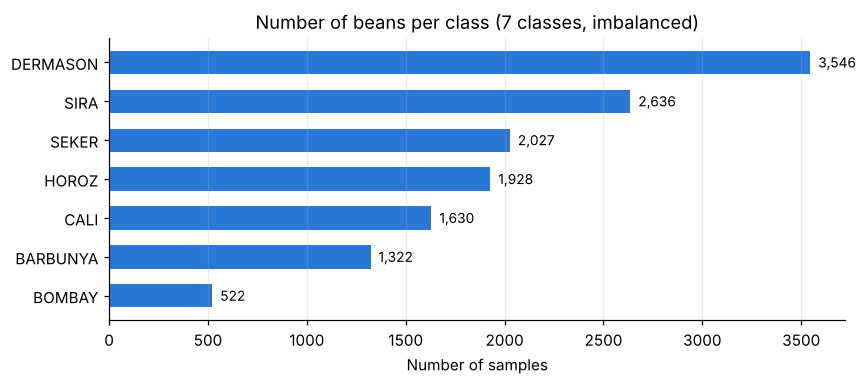

In [3]:
print("Data types:\n", df.dtypes.value_counts(), "\n")
print("Missing values in the whole table:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

counts = df["Class"].value_counts()
print("\nClass distribution:\n", pd.DataFrame({"count": counts,
                                               "percent": (100*counts/len(df)).round(1)}))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(counts.index[::-1], counts.values[::-1], color=PALETTE[0], height=0.6)
for y, v in enumerate(counts.values[::-1]):
    ax.text(v + 40, y, f"{v:,}", va="center", fontsize=9)
ax.set_title("Number of beans per class (7 classes, imbalanced)")
ax.set_xlabel("Number of samples"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Observation.** There are no missing values. The classes are **imbalanced**: DERMASON has about 26% of the samples and BOMBAY only about 4%. So we will:
* use a **stratified** train/test split, so both parts keep the same class proportions, and
* use **weighted** averages for the multi-class metrics.

The 68 duplicate rows are left in. They are real measurements that happen to coincide, and removing them barely changes the results.

In [4]:
# Feature scales: look at the min / max of every feature
df.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
Area,53048.2845,29324.0957,20420.0000,254616.0000
Perimeter,855.2835,214.2897,524.7360,1985.3700
MajorAxisLength,320.1419,85.6942,183.6012,738.8602
MinorAxisLength,202.2707,44.9701,122.5127,460.1985
AspectRation,1.5832,0.2467,1.0249,2.4303
Eccentricity,0.7509,0.0920,0.2190,0.9114
ConvexArea,53768.2002,29774.9158,20684.0000,263261.0000
EquivDiameter,253.0642,59.1771,161.2438,569.3744
Extent,0.7497,0.0491,0.5553,0.8662
Solidity,0.9871,0.0047,0.9192,0.9947


**Observation: very different scales.** `Area` goes up to about 254,000, while `ShapeFactor1` and `ShapeFactor2` are around 0.001–0.01. Without scaling, any **distance** (KNN) or **margin** (SVM) would be dominated almost entirely by `Area`, `ConvexArea` and `Perimeter`. We fix this in Step 5.

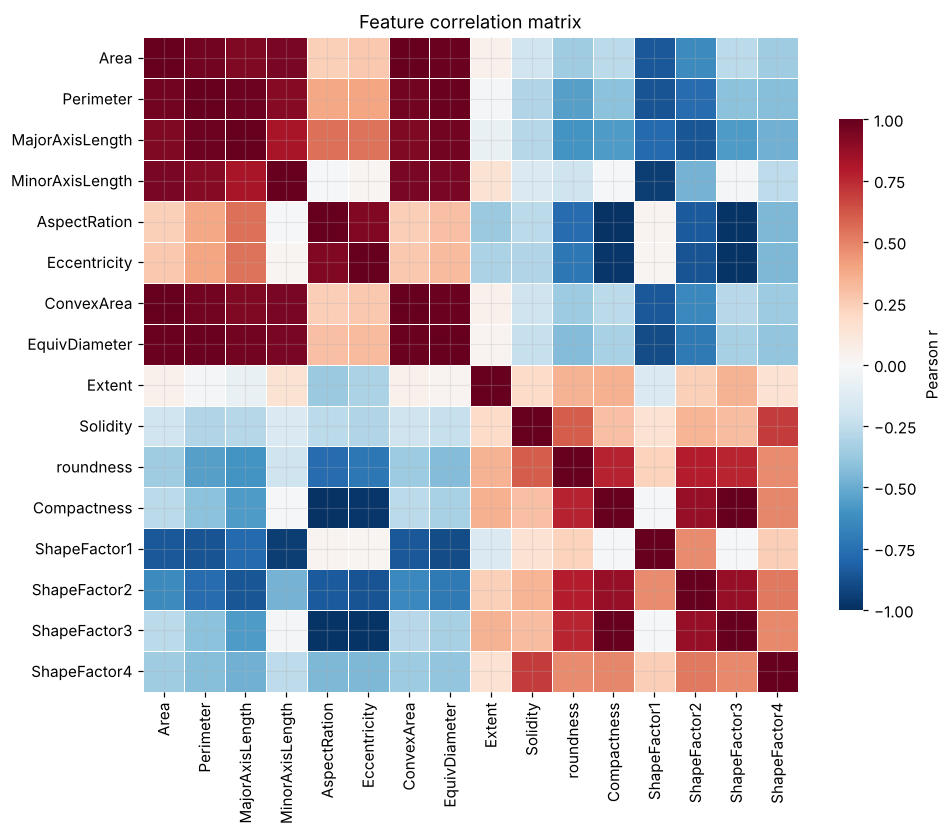

In [5]:
# Correlation between features (useful later for the Naive Bayes discussion)
plt.figure(figsize=(9, 7.5))
sns.heatmap(df.drop(columns="Class").corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.75, "label": "Pearson r"})
plt.title("Feature correlation matrix")
plt.tight_layout(); plt.show()

**Observation.** Many features are **strongly correlated**. For example, `Area`, `Perimeter`, `ConvexArea`, `EquivDiameter` and the axis lengths have r ≈ 0.9 or more, because they all measure *size*. Keep this in mind for **Naive Bayes (Step 9)**, whose central assumption is that features are conditionally independent.

## Step 4: Separate features and target, encode labels, and split into train and test sets
**Lecture 9, *Evaluating Classifier Performance*:**
* *Training set*: used to fit the models.
* *Validation set*: used to tune hyperparameters and choose between models.
* *Test set*: used **only once**, at the end, to estimate the generalization error. *"The test data can't be used for parameter tuning!"*
* A test split of *"Typically 80%, 20%"*. CS-15 gives 70/15/15 as another example and notes that *"these proportions are examples, not fixed rules."*

**Plan used here:**
* **80% training / 20% test**, stratified by class.
* Validation is done with **5-fold stratified cross-validation inside the training set**. This is Lecture 9's *"Solution: cross validation"*, which avoids setting aside a separate validation set and *"wasting valuable labeled data"*.

`LabelEncoder` turns the 7 class names into the integers 0–6, as scikit-learn's metrics expect.

In [6]:
X = df.drop(columns="Class")
y_text = df["Class"]

encoder = LabelEncoder()
y = encoder.fit_transform(y_text)
CLASS_NAMES = list(encoder.classes_)
print("Label encoding:", dict(zip(CLASS_NAMES, range(len(CLASS_NAMES)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"\nTraining set: {X_train.shape[0]:,} rows | Test set: {X_test.shape[0]:,} rows")
print("Class proportions kept by stratify (train vs test):")
print(pd.DataFrame({"train %": (100*np.bincount(y_train)/len(y_train)).round(1),
                    "test %":  (100*np.bincount(y_test)/len(y_test)).round(1)},
                   index=CLASS_NAMES))

# The same 5-fold stratified splitter is reused for every tuning step
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Label encoding: {'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}

Training set: 10,888 rows | Test set: 2,723 rows
Class proportions kept by stratify (train vs test):
          train %  test %
BARBUNYA      9.7     9.7
BOMBAY        3.8     3.8
CALI         12.0    12.0
DERMASON     26.1    26.0
HOROZ        14.2    14.2
SEKER        14.9    14.9
SIRA         19.4    19.4


## Step 5: Feature scaling with Z-score standardization
**Lecture 9, *Standardizing Numeric Data*:**
$$z = \frac{x-\mu}{\sigma}$$
*"the distance between the raw score and the population mean in units of the standard deviation"*. After scaling, every feature has mean 0 and standard deviation 1.

Why it matters for each model:
* **KNN:** Lecture 9's lab notes say *"Distance measures are strongly affected by the scale of the input data."*
* **SVM:** the margin $\frac{2}{\lVert w\rVert}$ and the RBF kernel $\exp(-\lVert x_i-x_j\rVert^2/2\sigma^2)$ are both distance-based (Lecture 10).
* **Logistic Regression:** gradient-based optimisation converges much faster when features are on the same scale.
* **Decision Tree / Gaussian NB:** not affected. A tree split is a threshold on one feature, and GNB fits a separate Gaussian per feature. We still scale them so that all five models receive identical inputs.

**Avoiding data leakage:** $\mu$ and $\sigma$ must be learned from the **training data only**. We put `StandardScaler` inside a `Pipeline`, so during cross-validation it is refitted on each training fold and never sees the validation fold or the test set.

In [7]:
# Demonstration only: what scaling does to the training data
demo = StandardScaler().fit(X_train)
X_train_scaled_demo = pd.DataFrame(demo.transform(X_train), columns=X.columns)
print("Before scaling (first 4 features):")
print(X_train.iloc[:, :4].describe().loc[["mean", "std"]].round(2))
print("\nAfter scaling (first 4 features):")
print(X_train_scaled_demo.iloc[:, :4].describe().loc[["mean", "std"]].round(2))

def make_pipeline(classifier):
    # Scaler + model; the scaler is fitted on whatever data .fit() receives
    return Pipeline([("scaler", StandardScaler()), ("clf", classifier)])

Before scaling (first 4 features):
          Area  Perimeter  MajorAxisLength  MinorAxisLength
mean  53018.07     855.02           320.05           202.22
std   29288.34     214.08            85.61            44.97

After scaling (first 4 features):
      Area  Perimeter  MajorAxisLength  MinorAxisLength
mean   0.0       -0.0              0.0             -0.0
std    1.0        1.0              1.0              1.0


## Step 6: Define the six evaluation metrics
**CS-15, *Methods and Metrics for Model Evaluation*:**
* **Accuracy** = Correct predictions / Total predictions
* **Precision** = TP / (TP + FP). *Of the beans predicted as class c, how many really are c?*
* **Recall** = TP / (TP + FN). *Of the beans that really are class c, how many did we find?*
* **F1-score** = 2 × (Precision × Recall) / (Precision + Recall). The harmonic mean of the two.

The other two metrics belong to the *"confusion-matrix based metrics … AUC-ROC"* that CS-15 says were covered in earlier modules:
* **AUC (Area Under the ROC Curve):** the ROC curve plots the True Positive Rate against the False Positive Rate as the decision threshold moves. AUC is the probability that the model gives a randomly chosen positive a higher score than a randomly chosen negative. 1.0 is perfect and 0.5 is random guessing. It uses the predicted **probabilities**, not just the labels.
* **MCC (Matthews Correlation Coefficient):** a correlation between actual and predicted labels that uses all four cells of the confusion matrix:
$$\text{MCC}=\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$$
It ranges from −1 to +1 (0 = no better than chance) and stays reliable when classes are imbalanced.

**From two classes to seven.** These formulas are written for one positive class. With 7 classes:
* Precision, Recall and F1 are computed **for each class (one-vs-rest)** and then **weighted by the class size** (`average="weighted"`).
* AUC uses **One-vs-Rest** (`multi_class="ovr"`, weighted). This is the same *one-vs-all* idea Lecture 10 uses for multi-class SVM: *"pos = data from class i, neg = data from classes other than i"*.
* MCC uses scikit-learn's built-in multi-class generalisation (Gorodkin's $R_K$ statistic).

In [8]:
def evaluate_model(name, model, X_te=None, y_te=None):
    # Predict on the held-out test set and return the 6 metrics
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)          # needed for AUC
    metrics = {
        "Accuracy":  accuracy_score(y_te, y_pred),
        "AUC":       roc_auc_score(y_te, y_proba, multi_class="ovr", average="weighted"),
        "Precision": precision_score(y_te, y_pred, average="weighted", zero_division=0),
        "Recall":    recall_score(y_te, y_pred, average="weighted", zero_division=0),
        "F1":        f1_score(y_te, y_pred, average="weighted", zero_division=0),
        "MCC":       matthews_corrcoef(y_te, y_pred),
    }
    print(f"===== {name} =====")
    for k, v in metrics.items():
        print(f"  {k:<9}: {v:.4f}")
    return metrics, y_pred, y_proba

# Results of every model are collected here
RESULTS, PREDICTIONS, PROBAS, FINAL_MODELS = {}, {}, {}, {}

def store(name, model, metrics, y_pred, y_proba):
    RESULTS[name], PREDICTIONS[name], PROBAS[name], FINAL_MODELS[name] = metrics, y_pred, y_proba, model

## Step 7: Model 1, Logistic Regression
**Theory (Lecture 11, *MLE – Logistic Regression* and *Generative vs Discriminative*):**
* Logistic Regression is a **discriminative** model. It *"model[s] P(Y | X) directly, without modelling P(X | Y)"*.
* Binary case: $P(y=1\mid x)=\sigma(\theta^\top x)=\frac{1}{1+e^{-\theta^\top x}}$.
* The parameters θ are found by **Maximum Likelihood Estimation**, which means maximising the Bernoulli log-likelihood. *"No closed form for θ ⇒ gradient ascent (equivalently, minimise the log-loss)."*
* With **7 classes**, scikit-learn uses the multinomial generalisation (**softmax**): one weight vector per class, $P(y=k\mid x)=\frac{e^{\theta_k^\top x}}{\sum_j e^{\theta_j^\top x}}$.
* Lecture 11 also shows that LR has *"precisely the form implied by the assumptions of a Gaussian Naive Bayes classifier"* (Step 9). This makes the two an interesting pair to compare.

**Settings:** `max_iter=2000` gives the solver (L-BFGS) enough iterations to converge. `C=1.0` is the default L2 regularisation strength.

In [9]:
log_reg = make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
log_reg.fit(X_train, y_train)

m, yp, ypr = evaluate_model("Logistic Regression", log_reg)
store("Logistic Regression", log_reg, m, yp, ypr)

===== Logistic Regression =====
  Accuracy : 0.9214
  AUC      : 0.9934
  Precision: 0.9222
  Recall   : 0.9214
  F1       : 0.9216
  MCC      : 0.9050


### Step 7a: Worked example, computing Precision, Recall and F1 by hand from the confusion matrix
To connect the CS-15 formulas to the numbers above, take one class, **DERMASON**, and treat it as *positive* and all other classes as *negative* (one-vs-rest):
* **TP** = DERMASON beans predicted as DERMASON (the diagonal cell)
* **FP** = other beans wrongly predicted as DERMASON (rest of that **column**)
* **FN** = DERMASON beans predicted as something else (rest of that **row**)

In [10]:
cm = confusion_matrix(y_test, PREDICTIONS["Logistic Regression"])
c = CLASS_NAMES.index("DERMASON")
TP = cm[c, c]
FP = cm[:, c].sum() - TP
FN = cm[c, :].sum() - TP
TN = cm.sum() - TP - FP - FN

precision_c = TP / (TP + FP)
recall_c    = TP / (TP + FN)
f1_c        = 2 * precision_c * recall_c / (precision_c + recall_c)
print(f"DERMASON  ->  TP={TP}, FP={FP}, FN={FN}, TN={TN}")
print(f"Precision = {TP}/({TP}+{FP}) = {precision_c:.4f}")
print(f"Recall    = {TP}/({TP}+{FN}) = {recall_c:.4f}")
print(f"F1        = 2*P*R/(P+R)      = {f1_c:.4f}")

# Cross-check with scikit-learn's per-class values
print("\nscikit-learn per-class report (Logistic Regression):")
print(classification_report(y_test, PREDICTIONS["Logistic Regression"],
                            target_names=CLASS_NAMES, digits=4))

DERMASON  ->  TP=644, FP=53, FN=65, TN=1961
Precision = 644/(644+53) = 0.9240
Recall    = 644/(644+65) = 0.9083
F1        = 2*P*R/(P+R)      = 0.9161

scikit-learn per-class report (Logistic Regression):
              precision    recall  f1-score   support

    BARBUNYA     0.9516    0.8906    0.9201       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9303    0.9417    0.9360       326
    DERMASON     0.9240    0.9083    0.9161       709
       HOROZ     0.9633    0.9508    0.9570       386
       SEKER     0.9303    0.9532    0.9416       406
        SIRA     0.8483    0.8805    0.8641       527

    accuracy                         0.9214      2723
   macro avg     0.9354    0.9321    0.9335      2723
weighted avg     0.9222    0.9214    0.9216      2723



The hand-computed DERMASON row matches scikit-learn's report. The **weighted avg** row at the bottom is what we report as Precision, Recall and F1: each class's score weighted by its *support* (number of test samples).

## Step 8: Model 2, Decision Tree Classifier
**Theory (Module 5; CS-15 *Interpretability in Decision Trees*):**
* A decision tree splits the data recursively, one feature threshold at a time (for example *"Perimeter ≤ 0.3?"*). At each node it picks the split that makes the child nodes as **pure** as possible, measured by **Gini impurity** $1-\sum_k p_k^2$ or **entropy** $-\sum_k p_k\log_2 p_k$.
* CS-15 points out that trees are **highly interpretable**: *"ML interpretability allows one to examine model's basis in its decision making process."*
* An unrestricted tree keeps splitting until every leaf is pure. It then fits the training data perfectly and **overfits**. CS-15 says: *"A model that performs very well on training data may still perform poorly on new data. This is called overfitting."*

**Tuning with cross-validation (Lecture 9: the test set cannot be used for tuning).** We search over `max_depth` (how deep the tree may grow) and `criterion` (gini or entropy), using 5-fold CV on the training set only.

Best parameters : {'clf__criterion': 'gini', 'clf__max_depth': 8}
Best CV accuracy: 0.9093


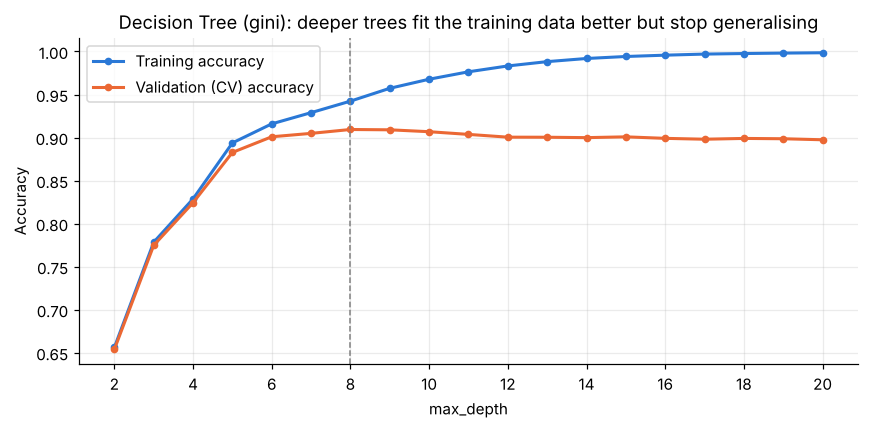

In [11]:
dt_grid = GridSearchCV(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    param_grid={"clf__max_depth": list(range(2, 21)) + [None],
                "clf__criterion": ["gini", "entropy"]},
    cv=CV, scoring="accuracy", n_jobs=-1, return_train_score=True)
dt_grid.fit(X_train, y_train)
print("Best parameters :", dt_grid.best_params_)
print(f"Best CV accuracy: {dt_grid.best_score_:.4f}")

# Visualise over/under-fitting: training vs validation accuracy as depth grows
cvr = pd.DataFrame(dt_grid.cv_results_)
best_crit = dt_grid.best_params_["clf__criterion"]
cvr = cvr[(cvr["param_clf__criterion"] == best_crit) & cvr["param_clf__max_depth"].notna()]
depths = cvr["param_clf__max_depth"].astype(int)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, cvr["mean_train_score"], marker="o", ms=4, color=PALETTE[0], label="Training accuracy")
ax.plot(depths, cvr["mean_test_score"],  marker="o", ms=4, color=PALETTE[1], label="Validation (CV) accuracy")
ax.axvline(dt_grid.best_params_["clf__max_depth"] or depths.max(), ls="--", color="grey", lw=1)
ax.set_xticks(range(2, 21, 2)); ax.set_xlabel("max_depth"); ax.set_ylabel("Accuracy")
ax.set_title(f"Decision Tree ({best_crit}): deeper trees fit the training data better but stop generalising")
ax.legend(); plt.tight_layout(); plt.show()

**Reading the plot.** Training accuracy keeps rising towards 100% as the tree grows deeper. Validation accuracy peaks and then flattens or drops, which is **overfitting** in action. The dashed line marks the depth chosen by cross-validation.

===== Decision Tree =====
  Accuracy : 0.9041
  AUC      : 0.9789
  Precision: 0.9038
  Recall   : 0.9041
  F1       : 0.9038
  MCC      : 0.8841


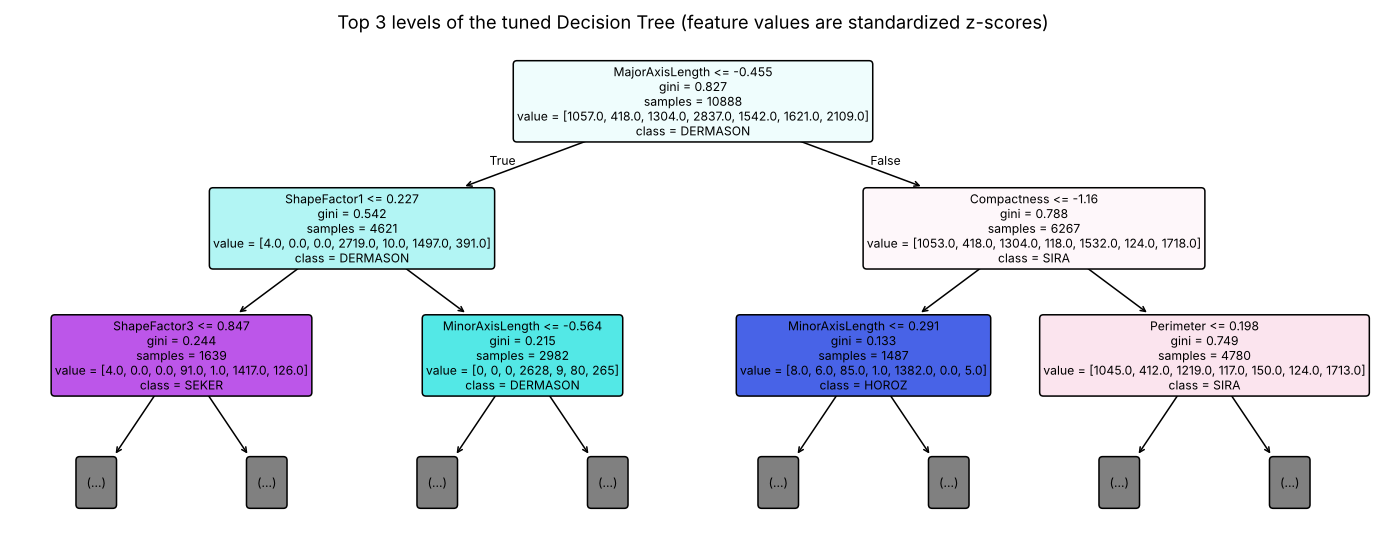

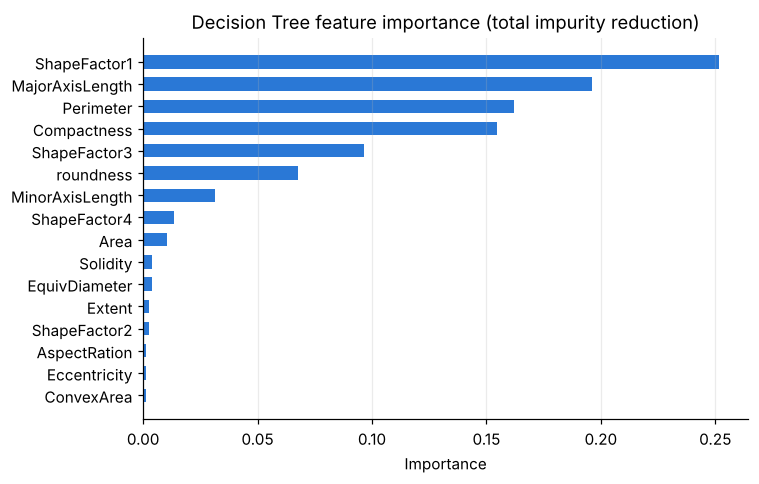

In [12]:
dt = dt_grid.best_estimator_            # already refitted on the full training set
m, yp, ypr = evaluate_model("Decision Tree", dt)
store("Decision Tree", dt, m, yp, ypr)

# Interpretability (CS-15): the top of the tree and the most important features
tree = dt.named_steps["clf"]
plt.figure(figsize=(16, 6))
plot_tree(tree, max_depth=2, feature_names=X.columns, class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=8, impurity=True)
plt.title("Top 3 levels of the tuned Decision Tree (feature values are standardized z-scores)")
plt.show()

imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color=PALETTE[0], height=0.6)
ax.set_title("Decision Tree feature importance (total impurity reduction)")
ax.set_xlabel("Importance"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Step 9: Model 3, K-Nearest Neighbor (KNN)
**Theory (Lecture 9, Instance Based Learning):**
* KNN is a **lazy learner**: *"Less time in training but more time in predicting"*. Training only *"store[s] all training examples"*.
* To classify a query $x_q$: compute its **distance** to every training point, choose the **k nearest**, and *"take vote among its k nearest neighbors"*.
* Distance is the **Minkowski** distance $d(i,j)=\left(\sum_f |x_{if}-x_{jf}|^h\right)^{1/h}$. With $h=2$ it is **Euclidean**, scikit-learn's default. With $h=1$ it is Manhattan.
* **Choosing k** (Lecture 9, *Hyper parameter "K"*):
  * Rule of thumb: $K=\sqrt{N}$.
  * **Elbow method**: plot the error for different k and pick the point where the curve flattens.
* **Distance-weighted KNN** (Lecture 9, *Variation*): closer neighbours get a larger vote, $w_i = 1/d(x_q,x_i)^2$. scikit-learn's `weights="distance"` uses $w_i=1/d$.
* *Curse of dimensionality*: KNN works best on low-dimensional data. With 16 features we are fine, but scaling (Step 5) is essential.

Below we try both ideas from the slides, the √N rule and the elbow curve. The elbow curve is computed with 5-fold CV on the training set, for uniform and distance-weighted voting.

Rule of thumb: K = sqrt(10888) = 104.3 -> 105


Best parameters : {'clf__n_neighbors': 21, 'clf__weights': 'distance'}
Best CV accuracy: 0.9272


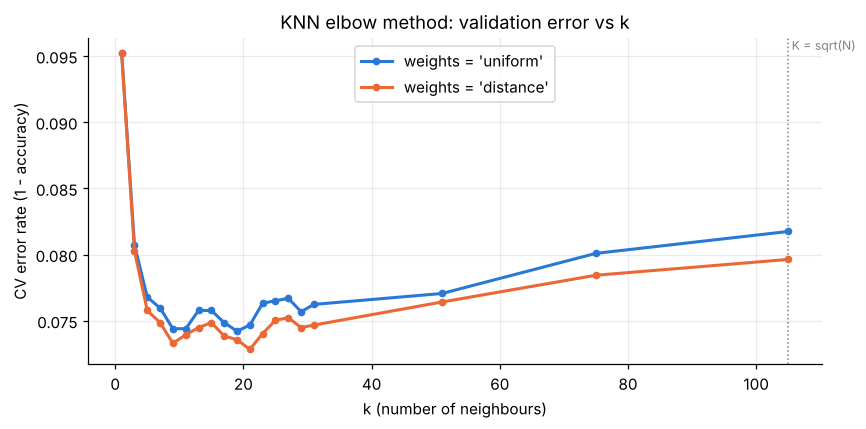

In [13]:
N = len(X_train)
k_sqrt = int(np.sqrt(N)) | 1                   # rule of thumb, forced to be odd
k_values = list(range(1, 32, 2)) + [51, 75, k_sqrt]
print(f"Rule of thumb: K = sqrt({N}) = {np.sqrt(N):.1f} -> {k_sqrt}")

knn_grid = GridSearchCV(
    make_pipeline(KNeighborsClassifier()),
    param_grid={"clf__n_neighbors": k_values, "clf__weights": ["uniform", "distance"]},
    cv=CV, scoring="accuracy", n_jobs=-1)
knn_grid.fit(X_train, y_train)
print("Best parameters :", knn_grid.best_params_)
print(f"Best CV accuracy: {knn_grid.best_score_:.4f}")

# Elbow plot: validation error vs k
r = pd.DataFrame(knn_grid.cv_results_)
fig, ax = plt.subplots(figsize=(8, 4))
for i, w in enumerate(["uniform", "distance"]):
    sub = r[r["param_clf__weights"] == w].sort_values("param_clf__n_neighbors")
    ax.plot(sub["param_clf__n_neighbors"], 1 - sub["mean_test_score"], marker="o", ms=4,
            color=PALETTE[i], label=f"weights = '{w}'")
ax.axvline(k_sqrt, ls=":", color="grey", lw=1)
ax.text(k_sqrt, ax.get_ylim()[1], " K = sqrt(N)", va="top", fontsize=8, color="grey")
ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("CV error rate (1 - accuracy)")
ax.set_title("KNN elbow method: validation error vs k")
ax.legend(); plt.tight_layout(); plt.show()

**Reading the plot.** Very small k (for example k = 1) is noisy because a single neighbour decides the class. The error drops quickly and then flattens: that is the *elbow*. Very large k, including the rule-of-thumb √N ≈ 105, slowly gets worse again because the vote is spread over beans that are far away and of other varieties. We use the k with the lowest CV error.

In [14]:
knn = knn_grid.best_estimator_
m, yp, ypr = evaluate_model("K-Nearest Neighbor", knn)
store("K-Nearest Neighbor", knn, m, yp, ypr)

===== K-Nearest Neighbor =====
  Accuracy : 0.9203
  AUC      : 0.9895
  Precision: 0.9213
  Recall   : 0.9203
  F1       : 0.9204
  MCC      : 0.9037


## Step 10: Model 4, Naive Bayes (Gaussian)
**Theory (Lecture 11, Bayesian Learning):**
* Naive Bayes is a **generative** model. It learns $P(Y)$ and $P(X\mid Y)$, then applies **Bayes' rule**: $P(Y\mid X)\propto P(Y)\,P(X\mid Y)$.
* **The "naive" assumption:** features are conditionally independent given the class, so $P(x\mid y)=\prod_i P(x_i\mid y)$.
* **Gaussian or Multinomial?** The slide's scikit-learn table says *Multinomial* is for *"counts / word frequencies"* and *Gaussian* is for *"continuous"* features. All 16 bean features are continuous measurements, some negative after scaling, so **Gaussian NB** is the right choice.
* **Continuous features, learning:** *"for each class $y_k$ and each continuous feature $X_i$ estimate the mean and variance"*. That gives one Gaussian $N(\mu_{ik},\sigma^2_{ik})$ per (feature, class) pair.
* **Prediction:** $\hat y = \arg\max_k P(y_k)\prod_i N(x_i;\mu_{ik},\sigma^2_{ik})$. *"In practice compare sums of logs"* to avoid underflow. scikit-learn does this, and adds a tiny `var_smoothing` to every variance. That is the continuous counterpart of Laplace smoothing in the slide's table.

**Expectation.** The EDA in Step 3 showed many strongly correlated size features. That **violates the independence assumption**. Lecture 11 warns: *"Correlated evidence is counted twice, which makes the posterior over-confident."* We expect GNB to do slightly worse than the other models, but it should still do reasonably well, because *"the argmax only needs the ranking of the two scores, not their exact values."*

In [15]:
gnb = make_pipeline(GaussianNB())
gnb.fit(X_train, y_train)

# What GNB learned: a mean (and variance) per feature per class - shown for 4 features
nb = gnb.named_steps["clf"]
print("Class priors P(y):")
print(pd.Series(nb.class_prior_, index=CLASS_NAMES).round(4).to_string())
print("\nLearned class means mu_ik (standardized units), first 4 features:")
print(pd.DataFrame(nb.theta_[:, :4], index=CLASS_NAMES, columns=X.columns[:4]).round(3))

m, yp, ypr = evaluate_model("Naive Bayes (Gaussian)", gnb)
store("Naive Bayes (Gaussian)", gnb, m, yp, ypr)

Class priors P(y):
BARBUNYA    0.0971
BOMBAY      0.0384
CALI        0.1198
DERMASON    0.2606
HOROZ       0.1416
SEKER       0.1489
SIRA        0.1937

Learned class means mu_ik (standardized units), first 4 features:
           Area  Perimeter  MajorAxisLength  MinorAxisLength
BARBUNYA  0.569      0.888            0.582            0.839
BOMBAY    4.109      3.410            3.182            3.832
CALI      0.765      0.941            1.040            0.755
DERMASON -0.715     -0.888           -0.860           -0.814
HOROZ     0.022      0.305            0.615           -0.401
SEKER    -0.449     -0.596           -0.803           -0.009
SIRA     -0.282     -0.273           -0.241           -0.252
===== Naive Bayes (Gaussian) =====
  Accuracy : 0.8979
  AUC      : 0.9902
  Precision: 0.9007
  Recall   : 0.8979
  F1       : 0.8981
  MCC      : 0.8773


## Step 11: Model 5, Support Vector Machine (SVM)
**Theory (Lecture 10, SVM):**
* **Maximum margin:** of all separating hyperplanes $w^\top x+b=0$, SVM picks the one with the **largest margin**. Training solves *"minimise $\frac12\lVert w\rVert^2$ such that $y_i(w^\top x_i+b)\ge1$"*.
* **Support vectors** are *"those datapoints that the margin pushes up against"*. They alone define the hyperplane.
* **Soft margin:** real data is noisy, so slack variables $\xi_i$ allow some errors: minimise $\frac12 w^\top w + C\sum\xi_i$. *"Parameter C can be viewed as a way to control overfitting."* A large C gives a narrow margin with few training errors. A small C gives a wide margin and more tolerance.
* **Kernel trick:** for non-linear boundaries, replace the dot product with a kernel $K(x_i,x_j)=\varphi(x_i)^\top\varphi(x_j)$. We compare the **linear** kernel $x_i^\top x_j$ with the **Gaussian / RBF** kernel $\exp\!\left(-\frac{\lVert x_i-x_j\rVert^2}{2\sigma^2}\right)$. In scikit-learn, `gamma` $=\frac{1}{2\sigma^2}$.
* **Multi-class:** SVM is a binary classifier. Lecture 10 describes *one-vs-all* and **one-vs-one**. scikit-learn's `SVC` uses **one-vs-one**: with 7 classes it trains $\binom{7}{2}=21$ binary SVMs that *"all vote for the label"*.
* **Probabilities for AUC:** an SVM outputs distances to the hyperplane, not probabilities. `probability=True` turns them into probabilities with Platt scaling (an internal 5-fold logistic calibration), so we can compute AUC.

**Tuning:** we search over kernel and C with 3-fold CV. Probabilities are switched off during the search to keep it fast.

In [16]:
svm_grid = GridSearchCV(
    make_pipeline(SVC(random_state=RANDOM_STATE)),
    param_grid={"clf__kernel": ["linear", "rbf"], "clf__C": [0.1, 1, 10]},
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="accuracy", n_jobs=-1)
svm_grid.fit(X_train, y_train)
print("CV accuracy for each (kernel, C):")
print(pd.DataFrame(svm_grid.cv_results_)
        .pivot(index="param_clf__C", columns="param_clf__kernel", values="mean_test_score")
        .round(4))
print("\nBest parameters:", svm_grid.best_params_)

CV accuracy for each (kernel, C):
param_clf__kernel  linear     rbf
param_clf__C                     
0.1                0.9268  0.9229
1.0                0.9272  0.9312
10.0               0.9276  0.9330

Best parameters: {'clf__C': 10, 'clf__kernel': 'rbf'}


In [17]:
best = svm_grid.best_params_
svm = make_pipeline(SVC(kernel=best["clf__kernel"], C=best["clf__C"],
                        probability=True, random_state=RANDOM_STATE))
svm.fit(X_train, y_train)

s = svm.named_steps["clf"]
print(f"Support vectors: {s.n_support_.sum():,} of {len(X_train):,} training points "
      f"({100*s.n_support_.sum()/len(X_train):.1f}%)")
print("Support vectors per class:", dict(zip(CLASS_NAMES, s.n_support_)))
print("Binary classifiers trained (one-vs-one):", len(CLASS_NAMES)*(len(CLASS_NAMES)-1)//2, "\n")

m, yp, ypr = evaluate_model("Support Vector Machine", svm)
store("Support Vector Machine", svm, m, yp, ypr)

Support vectors: 1,927 of 10,888 training points (17.7%)
Support vectors per class: {'BARBUNYA': np.int32(179), 'BOMBAY': np.int32(23), 'CALI': np.int32(203), 'DERMASON': np.int32(513), 'HOROZ': np.int32(202), 'SEKER': np.int32(188), 'SIRA': np.int32(619)}
Binary classifiers trained (one-vs-one): 21 



===== Support Vector Machine =====
  Accuracy : 0.9243
  AUC      : 0.9933
  Precision: 0.9243
  Recall   : 0.9243
  F1       : 0.9243
  MCC      : 0.9085


**Observation.** Only a fraction of the training points end up as support vectors. Lecture 10 lists this as an SVM advantage: *"Often a sparse set of support vectors – compact at test time."* SIRA and DERMASON, the two classes that overlap most, contribute the most support vectors. BOMBAY needs very few because it is clearly separated by size.

## Step 12: Compare all five models on the six metrics
All models were trained on the same 80% training data and are evaluated here on the **same untouched 20% test set**.

In [18]:
results_df = pd.DataFrame(RESULTS).T[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]]
results_df.index.name = "Model"
display(results_df.style.format("{:.4f}").highlight_max(axis=0, color="#cfe3fa")
        .set_caption("Test-set metrics (weighted averages for the multi-class metrics; best per column highlighted)"))

results_df.round(4).to_csv("model_comparison_results.csv")
print("Saved: model_comparison_results.csv")

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9214,0.9934,0.9222,0.9214,0.9216,0.9050
Decision Tree,0.9041,0.9789,0.9038,0.9041,0.9038,0.8841
K-Nearest Neighbor,0.9203,0.9895,0.9213,0.9203,0.9204,0.9037
Naive Bayes (Gaussian),0.8979,0.9902,0.9007,0.8979,0.8981,0.8773
Support Vector Machine,0.9243,0.9933,0.9243,0.9243,0.9243,0.9085


Saved: model_comparison_results.csv


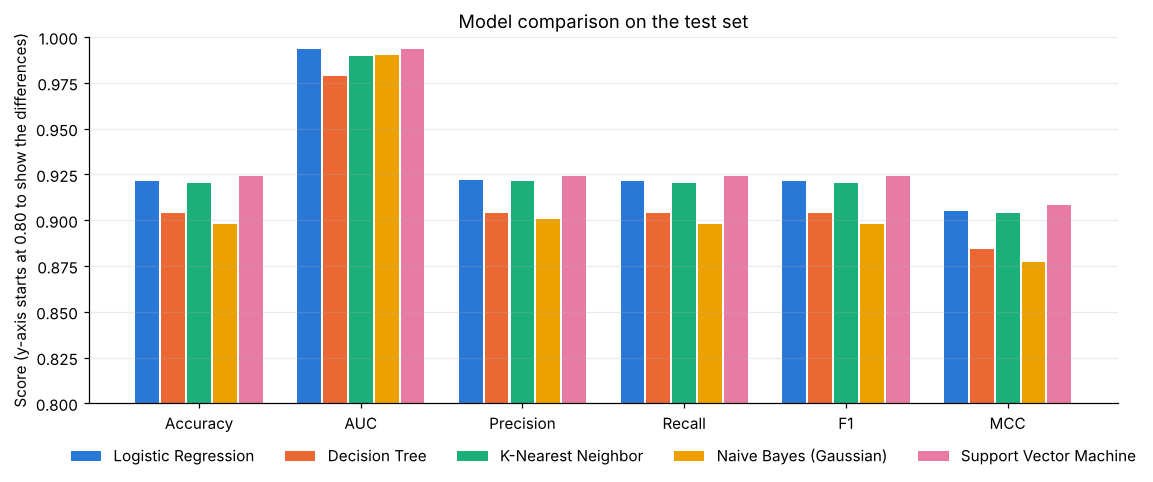

In [19]:
# Grouped bar chart: one colour per model, kept the same in every later chart
MODEL_COLORS = dict(zip(results_df.index, PALETTE))
metrics_order = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
x = np.arange(len(metrics_order)); width = 0.16

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, model in enumerate(results_df.index):
    ax.bar(x + (i - 2) * width, results_df.loc[model, metrics_order], width * 0.92,
           label=model, color=MODEL_COLORS[model])
ax.set_xticks(x, metrics_order)
ax.set_ylim(0.80, 1.0); ax.set_ylabel("Score (y-axis starts at 0.80 to show the differences)")
ax.set_title("Model comparison on the test set")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### Step 12a: Confusion matrices
Each row is the **actual** class and each column is the **predicted** class, with counts on the test set. The diagonal shows correct predictions. Large off-diagonal cells show which beans get confused with each other.

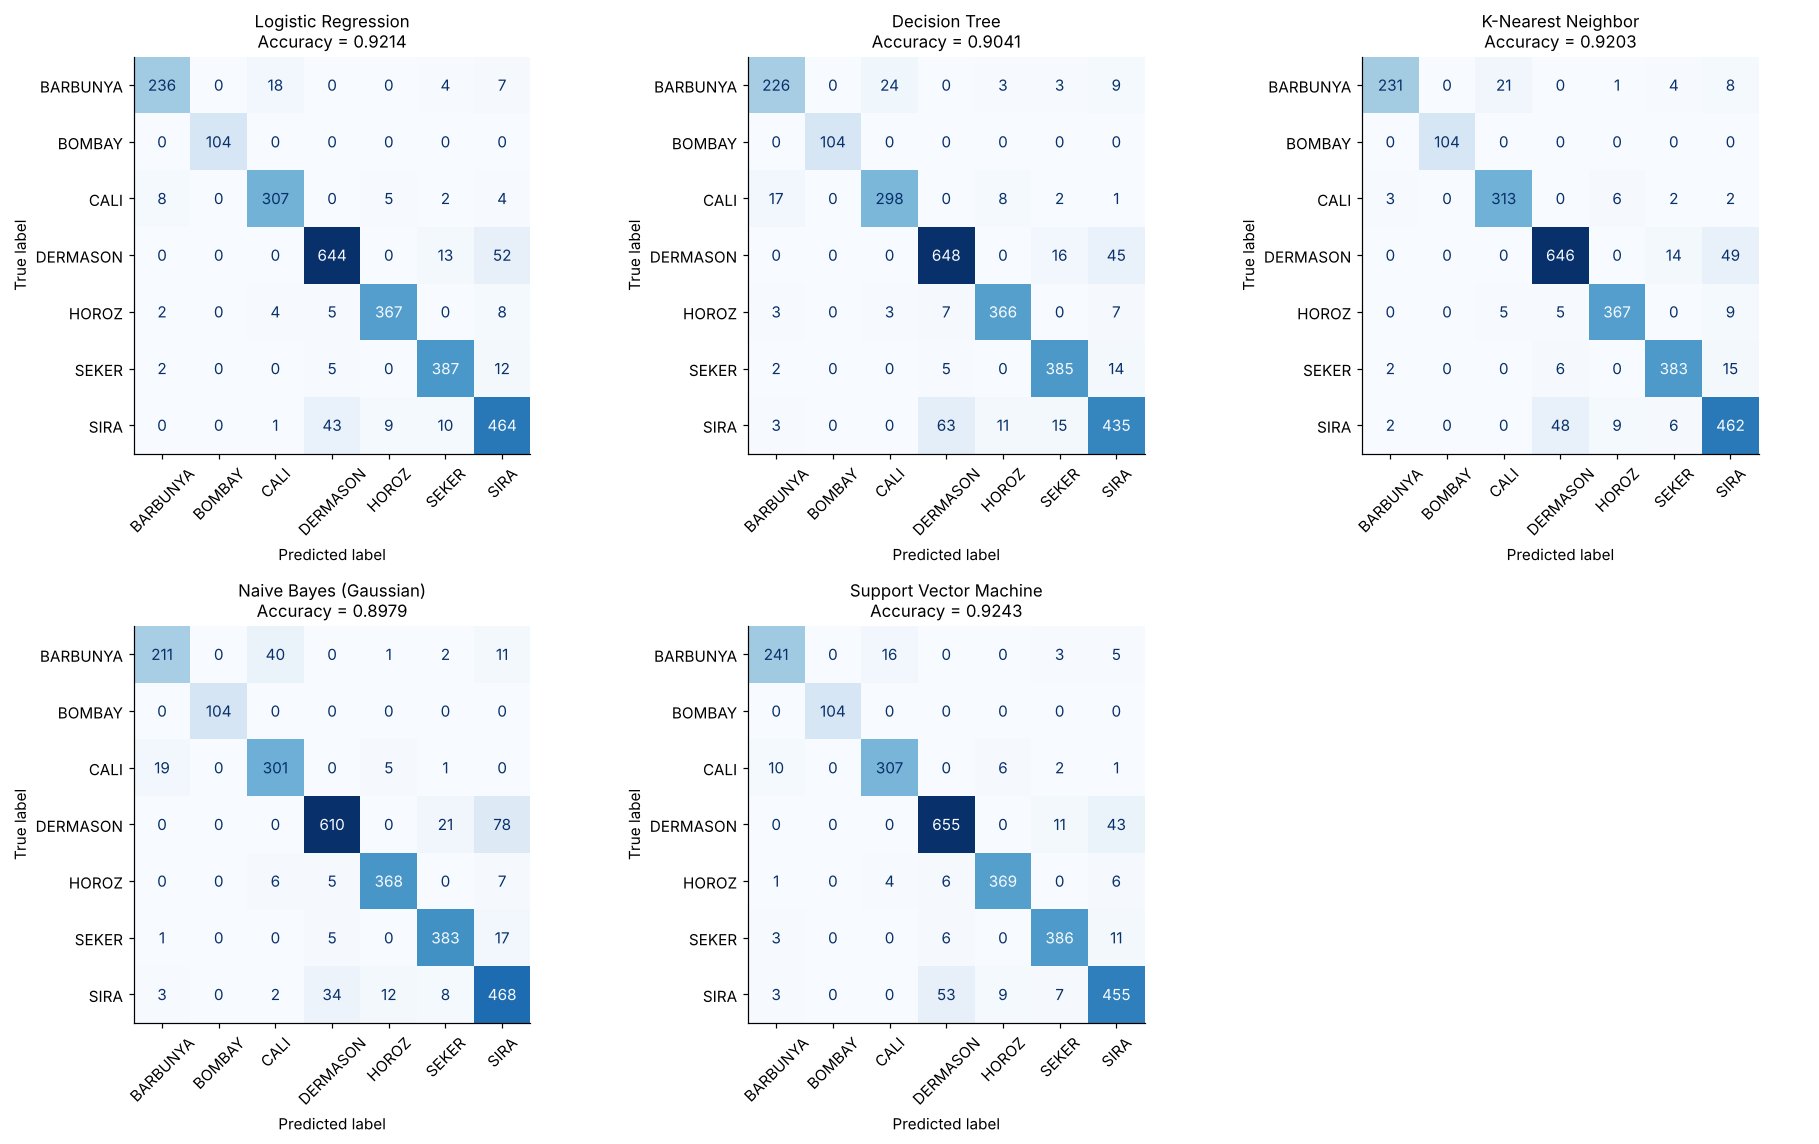

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
for ax, name in zip(axes.ravel(), results_df.index):
    ConfusionMatrixDisplay(confusion_matrix(y_test, PREDICTIONS[name]),
                           display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\nAccuracy = {RESULTS[name]['Accuracy']:.4f}", fontsize=11)
    ax.tick_params(axis="x", rotation=45); ax.grid(False)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

**What the confusion matrices show:**
* **BOMBAY** is classified almost perfectly by every model. It is by far the largest bean, so size alone separates it.
* Most errors come from three pairs: **SIRA ↔ DERMASON**, **BARBUNYA ↔ CALI** and **SIRA ↔ SEKER**. These varieties have overlapping sizes and shapes, so no model separates them completely.

### Step 12b: ROC curves (One-vs-Rest)
For each model we draw one ROC curve **per class** (that class against all the others). The AUC in the table above is the class-size-weighted average of these 7 per-class AUCs.

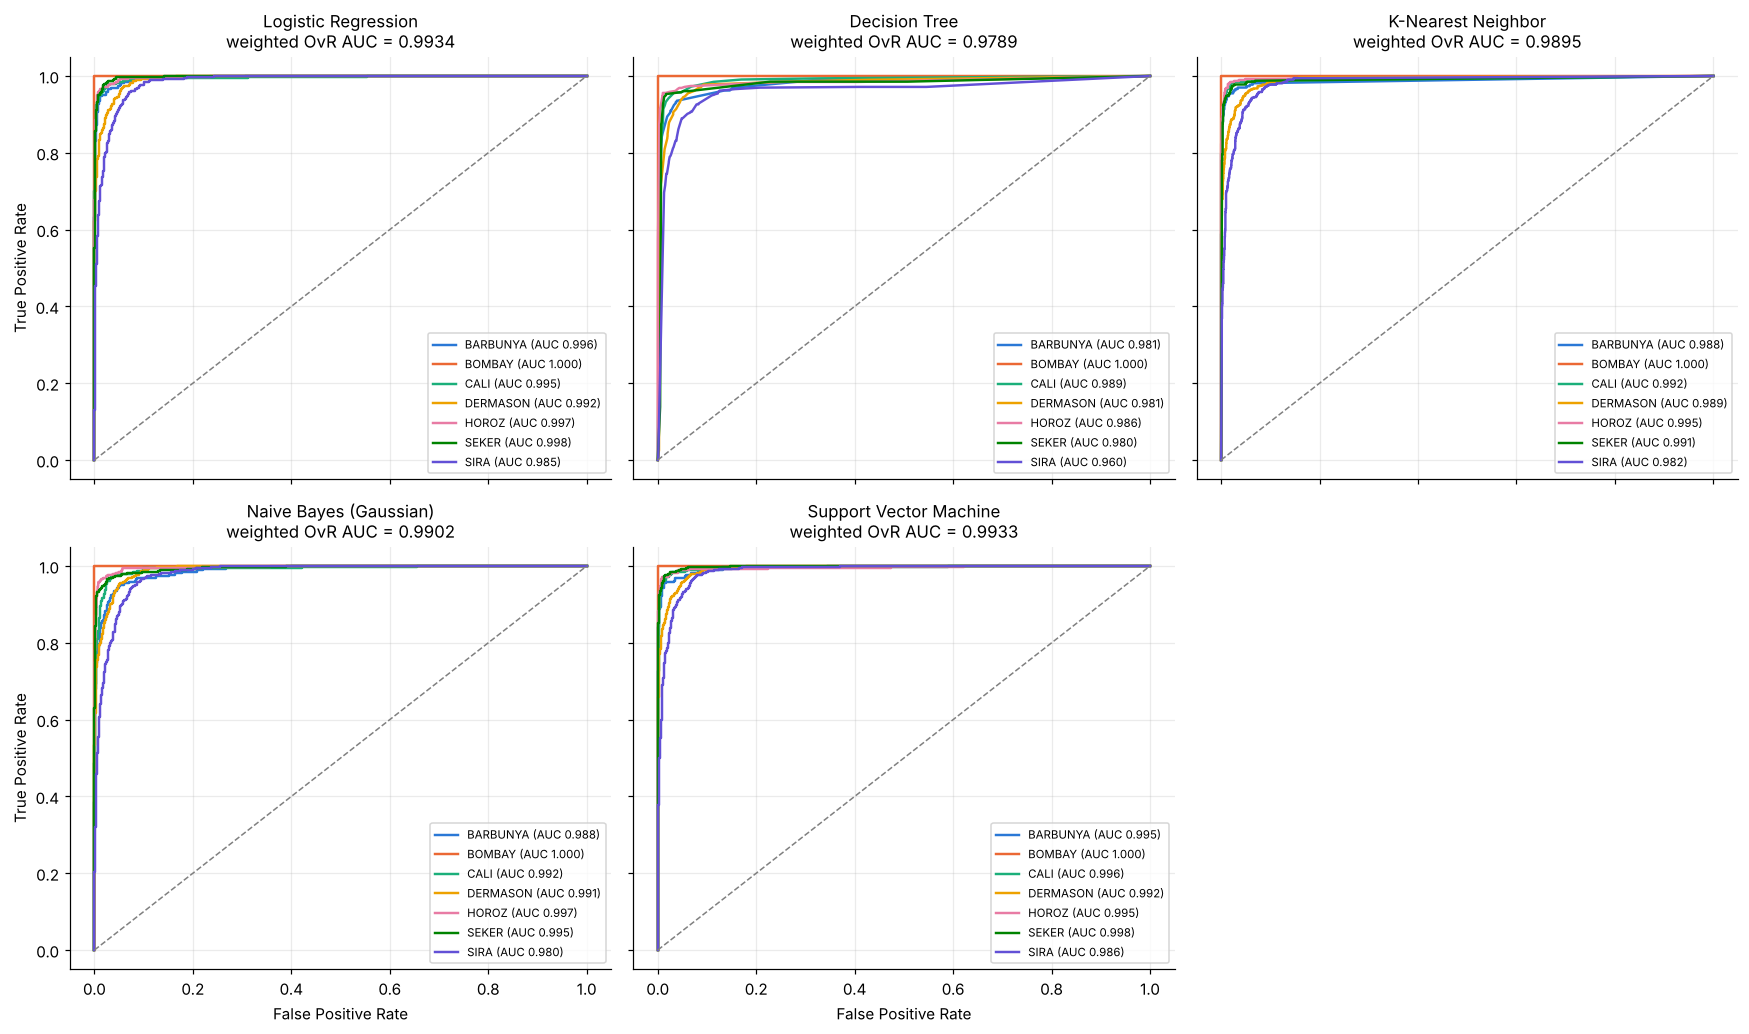

In [21]:
y_test_bin = label_binarize(y_test, classes=range(len(CLASS_NAMES)))
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), results_df.index):
    for k, cls in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], PROBAS[name][:, k])
        ax.plot(fpr, tpr, lw=1.6, color=PALETTE[k], label=f"{cls} (AUC {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
    ax.set_title(f"{name}\nweighted OvR AUC = {RESULTS[name]['AUC']:.4f}", fontsize=11)
    ax.legend(fontsize=7.5, loc="lower right")
for ax in axes[1]: ax.set_xlabel("False Positive Rate")
for ax in axes[:, 0]: ax.set_ylabel("True Positive Rate")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

**Why does the Decision Tree have the lowest AUC?** A single tree predicts probabilities from the class proportions in each leaf. With only 8 levels, all test beans that land in the same leaf get exactly the same probability. Its ROC curve is therefore made of a few straight segments (look at SIRA), while the other models produce smooth probability scores. Limiting the depth to 8 (Step 8) already helps a lot: a fully grown tree, whose leaves are pure, has an AUC of only about 0.93. This is one motivation for **Random Forests** (CS-12): averaging many bootstrapped trees gives smoother probabilities and less overfitting.

## Step 13: Check the ranking with cross-validation and confidence intervals
CS-15, *Comparing ML Models*, asks: *"Given that one hypothesis outperforms another over some sample of data, how probable is it that this hypothesis is more accurate in general?"* The slide's two steps are:
1. **estimate the confidence interval** of each model's accuracy, and
2. test whether the observed difference is **statistically significant**.

We do two simple checks:
* **10-fold cross-validated accuracy** on the training set. Lecture 9: *"For 10 folds, 10 scores will be returned … Then take average of that."*
* A **95% confidence interval for test accuracy**: $\text{acc}\pm1.96\sqrt{\frac{\text{acc}(1-\text{acc})}{n}}$ with $n$ = 2,723 test samples.

,10-fold CV mean,CV std,Test accuracy,95% CI low,95% CI high
Model,,,,,
Logistic Regression,0.9250,0.0066,0.9214,0.9113,0.9315
Decision Tree,0.9066,0.0074,0.9041,0.8931,0.9152
K-Nearest Neighbor,0.9268,0.0055,0.9203,0.9101,0.9305
Naive Bayes (Gaussian),0.8971,0.0077,0.8979,0.8865,0.9093
Support Vector Machine,0.9334,0.0070,0.9243,0.9144,0.9343


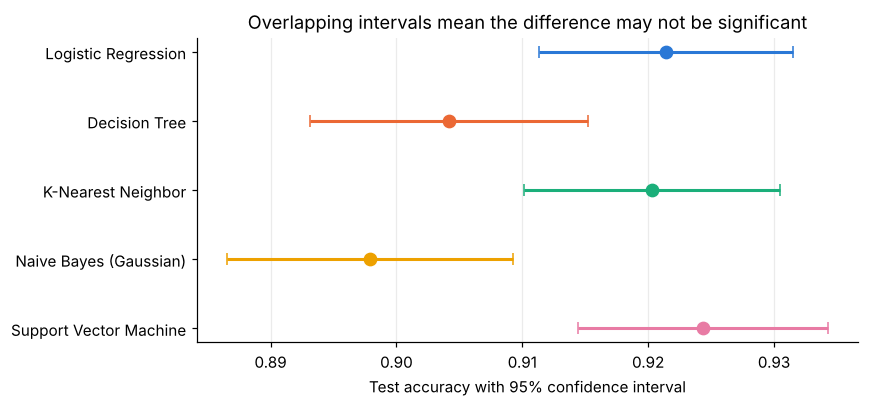

In [22]:
from sklearn.base import clone
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
n_test = len(y_test)
rows = []
for name, model in FINAL_MODELS.items():
    m = clone(model)
    if name == "Support Vector Machine":           # probabilities are not needed for accuracy
        m.set_params(clf__probability=False)
    scores = cross_val_score(m, X_train, y_train, cv=cv10, scoring="accuracy", n_jobs=-1)
    acc = RESULTS[name]["Accuracy"]
    half = 1.96 * np.sqrt(acc * (1 - acc) / n_test)
    rows.append({"Model": name, "10-fold CV mean": scores.mean(), "CV std": scores.std(),
                 "Test accuracy": acc, "95% CI low": acc - half, "95% CI high": acc + half})
cv_df = pd.DataFrame(rows).set_index("Model")
display(cv_df.style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(8, 3.8))
for i, name in enumerate(cv_df.index[::-1]):
    r = cv_df.loc[name]
    ax.errorbar(r["Test accuracy"], i, xerr=[[r["Test accuracy"] - r["95% CI low"]],
                [r["95% CI high"] - r["Test accuracy"]]], fmt="o", ms=8, capsize=4,
                color=MODEL_COLORS[name])
ax.set_yticks(range(len(cv_df)), cv_df.index[::-1])
ax.set_xlabel("Test accuracy with 95% confidence interval")
ax.set_title("Overlapping intervals mean the difference may not be significant")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Step 14: Conclusions

In [23]:
best_model = results_df["Accuracy"].idxmax()
print("Ranking by test accuracy:")
for rank, (name, row) in enumerate(results_df.sort_values("Accuracy", ascending=False).iterrows(), 1):
    print(f"  {rank}. {name:<24} Acc={row['Accuracy']:.4f}  AUC={row['AUC']:.4f}  "
          f"F1={row['F1']:.4f}  MCC={row['MCC']:.4f}")
print(f"\nBest model: {best_model}")

Ranking by test accuracy:
  1. Support Vector Machine   Acc=0.9243  AUC=0.9933  F1=0.9243  MCC=0.9085
  2. Logistic Regression      Acc=0.9214  AUC=0.9934  F1=0.9216  MCC=0.9050
  3. K-Nearest Neighbor       Acc=0.9203  AUC=0.9895  F1=0.9204  MCC=0.9037
  4. Decision Tree            Acc=0.9041  AUC=0.9789  F1=0.9038  MCC=0.8841
  5. Naive Bayes (Gaussian)   Acc=0.8979  AUC=0.9902  F1=0.8981  MCC=0.8773

Best model: Support Vector Machine


**Summary of findings** (your exact numbers can differ in the 3rd–4th decimal place depending on the scikit-learn version):

| Model | What happened | Link to the theory in the slides |
|---|---|---|
| **SVM (RBF kernel, C = 10)** | Best on 5 of the 6 metrics. Its AUC is tied with LR (0.9933 vs 0.9934) | The kernel trick gives a flexible non-linear boundary, and the soft margin (C) controls overfitting (Lecture 10) |
| **Logistic Regression** | Almost as good as SVM, with the highest AUC | Shape features separate the classes almost linearly once standardized. LR is the discriminative counterpart of GNB (Lecture 11) |
| **KNN (k = 21, distance-weighted)** | Close behind | Works well after Z-score scaling. k was chosen with the elbow method on CV error (Lecture 9) |
| **Gaussian NB** | Lowest accuracy, F1 and MCC, but its AUC (0.990) beats KNN and the Decision Tree | The size features are strongly correlated, which breaks the conditional-independence assumption. The ranking of classes (AUC) is still good, but the hard decisions suffer (Lecture 11) |
| **Decision Tree (depth 8)** | 4th on accuracy, lowest AUC | Highly interpretable (CS-15), but a single tree has high variance and gives coarse probabilities. Ensembles fix this (CS-12) |

**Key takeaways:**
1. **Preprocessing matters as much as the model.** Standardization (Lecture 9) is essential for KNN, SVM and LR on this dataset.
2. **Tune on validation folds, never on the test set** (Lecture 9). Every hyperparameter here was chosen with CV on the training set.
3. **Use more than accuracy.** MCC and weighted F1 account for the imbalance (BOMBAY is only about 4% of the data). AUC measures how well the predicted probabilities rank the classes.
4. **Small differences may not be significant.** The 95% intervals of SVM, LR and KNN overlap, so their ranking could change with a different split. The gap between SVM and Naive Bayes is larger than both intervals (Step 13, CS-15).
5. **Natural next step:** a **Random Forest** or **Gradient Boosting / XGBoost** (CS-12/13) usually improves on the single Decision Tree by combining many trees.

## Step 15: Save the trained models and the test data for the Streamlit app
The Streamlit app must **not retrain** anything. It loads the five fitted pipelines from `model/` and evaluates them on an uploaded CSV.
* Each saved pipeline already contains its `StandardScaler`, so no separate preprocessing file is needed.
* `label_encoder.pkl` converts the numeric predictions back to bean names.
* `test_data.csv` is the untouched 20% test split (16 features + `Class`), which is what you upload in the app.

In [ ]:
import joblib, re

os.makedirs("model", exist_ok=True)
for name, mdl in FINAL_MODELS.items():
    fname = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    joblib.dump(mdl, f"model/{fname}.pkl")
joblib.dump(encoder, "model/label_encoder.pkl")

test_df = X_test.copy()
test_df["Class"] = encoder.inverse_transform(y_test)
test_df.to_csv("test_data.csv", index=False)

for f in sorted(os.listdir("model")):
    print(f"model/{f:<32} {os.path.getsize('model/' + f) / 1024:8.1f} KB")
print(f"test_data.csv: {test_df.shape[0]} rows x {test_df.shape[1]} columns")